# Eval results summary

For each dataset, compare the 5 models (3 hints, 1 mix hint, 1 GEM) across all KV cache ratios.

In [4]:
import json, re
from pathlib import Path
from collections import defaultdict
import matplotlib.pyplot as plt

RESULTS_DIR = Path("eval_results")
PREFIX = "q4_dim16_sink16_"
MODELS = {
    "local": "Local hint",
    "retrieval_hint": "Retrieval hint",
    "summary_hint": "Summary hint",
    "mixhint": "Mix hint",
    "gem": "GEM",
}

# results[dataset][model] = {ratio: score}
results = defaultdict(dict)
for f in sorted(RESULTS_DIR.glob(PREFIX + "*.json")):
    d = json.loads(f.read_text())
    tag = next((m for m in sorted(MODELS, key=len, reverse=True) if f.stem.startswith(PREFIX + m + "_")), None)
    if tag is None:
        continue
    for ds, v in d["datasets"].items():
        results[ds][tag] = {float(r): s for r, s in v["score"].items()}

for ds, by_model in results.items():
    print(ds, sorted(by_model))

mrcr ['gem', 'local', 'mixhint', 'retrieval_hint', 'summary_hint']
scbench_summary ['gem', 'local', 'mixhint', 'retrieval_hint', 'summary_hint']
squad ['gem', 'local', 'mixhint', 'retrieval_hint', 'summary_hint']


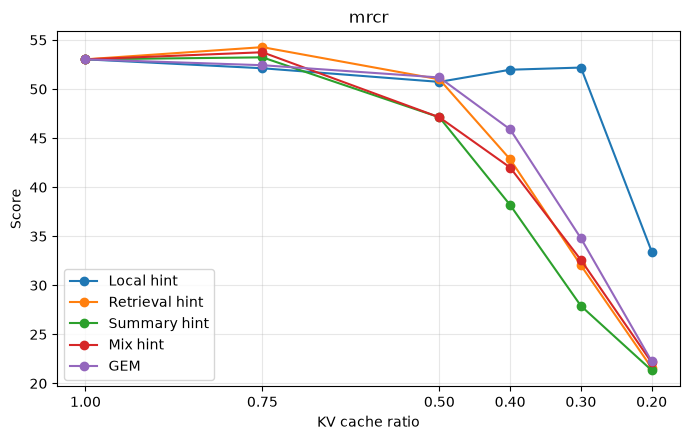

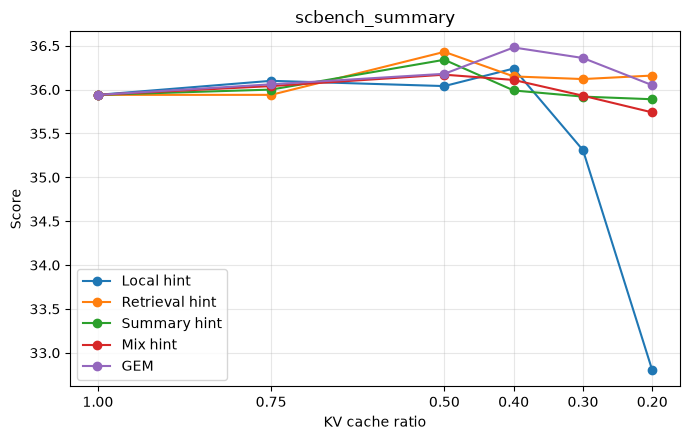

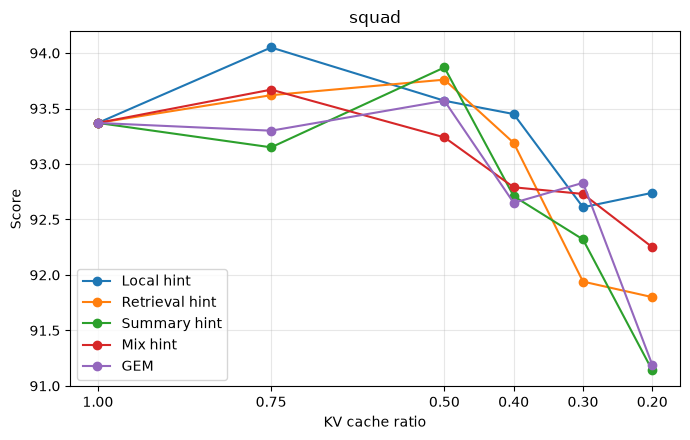

In [ ]:
for ds, by_model in sorted(results.items()):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for tag, label in MODELS.items():
        if tag not in by_model:
            continue
        ratios = sorted(by_model[tag], reverse=True)
        ax.plot(ratios, [by_model[tag][r] for r in ratios], marker="o", label=label)
    all_ratios = sorted({r for m in by_model.values() for r in m}, reverse=True)
    ax.set_xticks(all_ratios)
    ax.invert_xaxis() 
    ax.set_xlabel("KV cache ratio")
    ax.set_ylabel("Score")
    ax.set_title(ds)
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()